# Market regimes with HMM vs. MDL segmentation: data, splits and baseline

This notebook covers steps 2 to 5 of the project workflow for the idea in
[`research/idea_market_regimes_hmm_mdl.md`](../../research/idea_market_regimes_hmm_mdl.md):

1. **Data.** Download hourly Binance spot candles, validate them, look at descriptive statistics.
2. **Preprocessing and split.** Build daily returns and realized variance, decide the preprocessing, create chronological train / dev / test splits, check for leakage.
3. **Baseline.** Define the task, the metrics and the evaluation protocol, and score fixed baselines.
4. **Method fit.** First fits of the two proposed methods (hidden Markov model, minimum description length segmentation) to check that they suit the data.

The literature review is in [`research/literature/literature_review.md`](../../research/literature/literature_review.md)
and the conclusions are written up in [`research/market_regimes_writeup.md`](../../research/market_regimes_writeup.md).

Reusable code lives in `src/scripts/binance_data.py` and `src/scripts/regimes.py`, with tests in `tests/`.

In [1]:
import sys
import time
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

sys.path.append("../scripts")
import binance_data as bd
import regimes as rg

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)

SYMBOLS = bd.DEFAULT_SYMBOLS        # BTC, ETH, BNB, SOL, XRP against USDT
MAIN = "BTCUSDT"                    # asset used for the detailed analysis
DATA_END = date(2026, 10, 9)        # fixed so that reruns give the same data
TRAIN_END, DEV_END = "2022-12-31", "2024-12-31"
DAYS_PER_YEAR = 365                 # crypto trades every day

# Chart style: one fixed colour per series, thin lines, quiet grid.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES_COLOR = dict(zip(SYMBOLS, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))
plt.rcParams.update({
    "figure.dpi": 90, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 1.2, "legend.frameon": False, "font.size": 9.5,
})

def mark_splits(ax):
    # Vertical lines at the train / dev and dev / test boundaries.
    for boundary in (TRAIN_END, DEV_END):
        ax.axvline(pd.Timestamp(boundary, tz="UTC"), color=MUTED, linewidth=0.8, linestyle=(0, (4, 3)))

## 1. Data

**What the idea needs.** A long, clean price history of liquid crypto pairs, fine enough to measure
volatility inside a day. No labels are needed, since regime detection is unsupervised.

**Source.** [data.binance.vision](https://data.binance.vision) publishes Binance's complete candle history as
zipped CSV files, free and without an API key. We take **hourly spot candles** for five large pairs from each
pair's listing date to 2026-10-09. Hourly bars are enough to compute a daily realized variance from 24
intraday returns, and they keep the download small (22 MB in total).

The cell below downloads anything that is missing into `data/binance_spot_1h/` (ignored by git) and loads it.

In [2]:
hourly = {}
for symbol in SYMBOLS:
    path = bd.klines_path(symbol, "1h")
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        bd.download_klines(symbol, "1h", end=DATA_END).to_parquet(path)
    hourly[symbol] = bd.load_klines(symbol, "1h").loc[: pd.Timestamp(DATA_END, tz="UTC") + pd.Timedelta(hours=23)]

hourly[MAIN].head(3)

,open,high,low,close,volume,quote_volume,trade_count,taker_buy_volume
open_time,,,,,,,,
2017-08-17 04:00:00+00:00,"4,261.4800","4,313.6200","4,261.3200","4,308.8300",47.1810,"202,366.1384",171.0000,35.1605
2017-08-17 05:00:00+00:00,"4,308.8300","4,328.6900","4,291.3700","4,315.3200",23.2349,"100,304.8236",102.0000,21.4481
2017-08-17 06:00:00+00:00,"4,330.2900","4,345.4500","4,309.3700","4,324.3500",7.2297,"31,282.3127",36.0000,4.8029


### 1.1 Validation

Checks on the raw hourly bars: coverage of the hourly grid, duplicates, bars that do not start on the hour,
impossible prices (high below low, close outside the high-low range), and hours without any trade.

In [3]:
def validate(df):
    grid = pd.date_range(df.index[0].floor("h"), df.index[-1].floor("h"), freq="h")
    covered = df.index.floor("h").unique()
    missing = grid.difference(covered)
    # Group consecutive missing hours into outages.
    outage_id = (pd.Series(missing).diff() != pd.Timedelta(hours=1)).cumsum() if len(missing) else pd.Series(dtype=int)
    outages = pd.Series(missing).groupby(outage_id).agg(["first", "size"]) if len(missing) else pd.DataFrame()
    bad_price = (df["high"] < df["low"]) | (df["close"] > df["high"]) | (df["close"] < df["low"]) | (df[["open", "high", "low", "close"]] <= 0).any(axis=1)
    return {
        "first bar": df.index[0].strftime("%Y-%m-%d"),
        "last bar": df.index[-1].strftime("%Y-%m-%d"),
        "bars": len(df),
        "missing hours": len(missing),
        "share missing %": 100 * len(missing) / len(grid),
        "outages": len(outages),
        "longest outage (h)": int(outages["size"].max()) if len(outages) else 0,
        "last outage": outages["first"].max().strftime("%Y-%m-%d") if len(outages) else "",
        "off-hour bars": int(((df.index.minute != 0) | (df.index.second != 0)).sum()),
        "duplicates": int(df.index.duplicated().sum()),
        "bad prices": int(bad_price.sum()),
        "zero-volume bars": int((df["volume"] == 0).sum()),
        "NaN cells": int(df.isna().sum().sum()),
    }

validation = pd.DataFrame({s: validate(hourly[s]) for s in SYMBOLS}).T
validation

,first bar,last bar,bars,missing hours,share missing %,outages,longest outage (h),last outage,off-hour bars,duplicates,bad prices,zero-volume bars,NaN cells
BTCUSDT,2017-08-17,2026-10-09,80053,127,0.1584,28,32,2023-03-24,43,0,0,4,0
ETHUSDT,2017-08-17,2026-10-09,80053,127,0.1584,28,32,2023-03-24,43,0,0,6,0
BNBUSDT,2017-11-06,2026-10-09,78117,120,0.1534,27,32,2023-03-24,43,0,0,5,0
SOLUSDT,2020-08-11,2026-10-09,53999,19,0.0352,10,4,2023-03-24,0,0,0,3,0
XRPUSDT,2018-05-04,2026-10-09,73849,87,0.1177,25,10,2023-03-24,0,0,0,4,0


In [4]:
# The off-hour bars: where are they?
off = hourly[MAIN].index[(hourly[MAIN].index.minute != 0) | (hourly[MAIN].index.second != 0)]
print(f"{MAIN}: {len(off)} off-hour bars, from {off.min()} to {off.max()}")
hourly[MAIN].loc["2018-02-07 23:00":"2018-02-09 11:00", ["open", "close", "volume"]]

BTCUSDT: 43 off-hour bars, from 2018-02-09 09:28:14.789000+00:00 to 2018-02-11 03:28:14.789000+00:00


,open,close,volume
open_time,,,
2018-02-07 23:00:00+00:00,"7,781.0000","7,599.0000","4,304.2778"
2018-02-08 00:00:00+00:00,"7,599.0000","7,784.0200","1,521.5373"
2018-02-09 09:28:14.789000+00:00,"7,789.9000","8,180.5000","1,451.8964"
2018-02-09 10:28:14.789000+00:00,"8,179.8000","8,301.0100","1,252.6179"


**Findings.**

- **Coverage is very good.** Less than 0.2% of hours are missing for every pair, and no pair has duplicates,
  impossible prices or NaNs.
- **Missing hours are exchange outages**, not random holes: the same dates are missing for all pairs listed
  at the time. Almost all of them are in 2017 to 2021, the last one in March 2023.
- **One long outage:** Binance was down for about 32 hours on 8 and 9 February 2018. When trading resumed,
  the bars started at 09:28:14 instead of on the hour, and stayed off-grid for 43 bars (BTC, ETH and BNB;
  SOL and XRP were not listed yet). The prices are valid, only the bar boundaries are shifted, so we keep
  these bars and assign them to the day they start in.
- **A handful of zero-volume bars** sit at the edges of outages. They carry the last price and are harmless.

As an independent check, the next cell compares the BTC bars with a second copy of the same market that was
already in `data/` (one-minute candles from 2020), aggregated to hours.

In [5]:
minute_file = bd.DATA_DIR / "btcusdt_spot_1m" / "btcusdt_1m_kline_20200101_to_20261009.parquet"
if minute_file.exists():
    minute = pd.read_parquet(minute_file, columns=["datetime", "open", "high", "low", "close", "volume"]).set_index("datetime")
    from_minutes = minute.resample("1h").agg({"open": "first", "high": "max", "low": "min", "close": "last", "volume": "sum"})
    both = hourly[MAIN].join(from_minutes, rsuffix="_1m", how="inner")
    rel_diff = pd.DataFrame({c: (both[c] - both[c + "_1m"]).abs() / both[c] for c in ["open", "high", "low", "close", "volume"]})
    crosscheck = pd.DataFrame({
        "hours compared": len(both),
        "hours differing by > 0.01%": (rel_diff > 1e-4).sum(),
        "largest relative difference": rel_diff.max(),
    })
    print(f"1-minute file: {len(minute):,} rows, {minute.index[0]} to {minute.index[-1]}")
    display(crosscheck)
else:
    print("1-minute cross-check file not present, skipping")

1-minute file: 3,560,060 rows, 2020-01-01 00:00:00+00:00 to 2026-10-09 23:59:00+00:00


,hours compared,hours differing by > 0.01%,largest relative difference
open,59345,0,0.0000
high,59345,1,0.0048
low,59345,1,0.0043
close,59345,2,0.0015
volume,59345,7,0.3148


The two copies agree: over 59,345 common hours, the open never differs, high, low and close differ by more
than 0.01% in at most 2 hours, and volume in 7. The one-minute file is itself missing about 2,500 minutes,
which accounts for these. The hourly download is trustworthy.

## 2. From hourly bars to daily observations

A regime lasts days to months, so the unit of analysis is the **UTC day**. For each day we compute:

- `ret`: the close-to-close log return, $r_t = \log(C_t / C_{t-1})$.
- `rv`: the **realized variance**, the sum of the 24 squared hourly log returns. It measures the same thing
  as $r_t^2$ (that day's variance) but with far less noise, because it uses 24 observations instead of one.
- `volume`: traded value in USDT.
- `complete`: whether all 24 hourly bars are present. Days hit by an outage have an understated `rv`.

In [6]:
daily = {s: rg.daily_bars(hourly[s]) for s in SYMBOLS}

def describe(d):
    r = d["ret"]
    return {
        "first day": d.index[0].strftime("%Y-%m-%d"),
        "days": len(d),
        "incomplete days": int((~d["complete"]).sum()),
        "mean return %/day": 100 * r.mean(),
        "volatility %/day": 100 * r.std(),
        "volatility %/year": 100 * r.std() * np.sqrt(DAYS_PER_YEAR),
        "skewness": r.skew(),
        "excess kurtosis": r.kurt(),
        "worst day %": 100 * r.min(),
        "worst day": r.idxmin().strftime("%Y-%m-%d"),
        "best day %": 100 * r.max(),
        "mean rv / mean r^2": d["rv"].mean() / (r**2).mean(),
    }

pd.DataFrame({s: describe(daily[s]) for s in SYMBOLS}).T

,first day,days,incomplete days,mean return %/day,volatility %/day,volatility %/year,skewness,excess kurtosis,worst day %,worst day,best day %,mean rv / mean r^2
BTCUSDT,2017-08-18,3340,29,0.0886,3.5317,67.4721,-0.9506,15.9643,-50.2607,2020-03-12,20.2952,1.1211
ETHUSDT,2017-08-18,3340,29,0.0631,4.5655,87.2231,-0.8739,12.1037,-59.0534,2020-03-12,23.3750,1.0380
BNBUSDT,2017-11-07,3259,28,0.1890,4.8923,93.4673,0.3294,21.7555,-58.2287,2020-03-12,53.2404,1.0762
SOLUSDT,2020-08-12,2250,10,0.1555,5.9388,113.4602,-0.2110,8.4276,-54.9008,2022-11-09,37.7554,1.0996
XRPUSDT,2018-05-05,3080,25,0.0146,5.1064,97.5582,0.5888,18.8183,-53.8657,2020-12-23,54.8698,1.0348


**Sizes.** BTC and ETH have 3,340 daily observations (9.1 years), BNB and XRP about 3,100 to 3,260, SOL 2,250.
That is plenty for models with a handful of parameters: a 3-state Gaussian HMM has 14, each MDL segment has 2.
It is small for anything data-hungry, which is one reason to keep the models simple. The hourly series (up to
80,000 bars per pair) is available if a later experiment needs more observations.

**Returns are far from Gaussian.** Excess kurtosis is between 8 and 22 (a Gaussian has 0), and the worst
day of every pair is a fall of 50 to 59%. For BTC, ETH and BNB that day is 12 March 2020. Any model that
assumes one Gaussian for all days will be badly wrong in the tails.

**Realized variance is consistent with squared returns.** The ratio of their means is between 1.03 and 1.12,
close to the value of 1 expected if hourly returns were uncorrelated. Realized variance is therefore a valid
proxy for the daily variance.

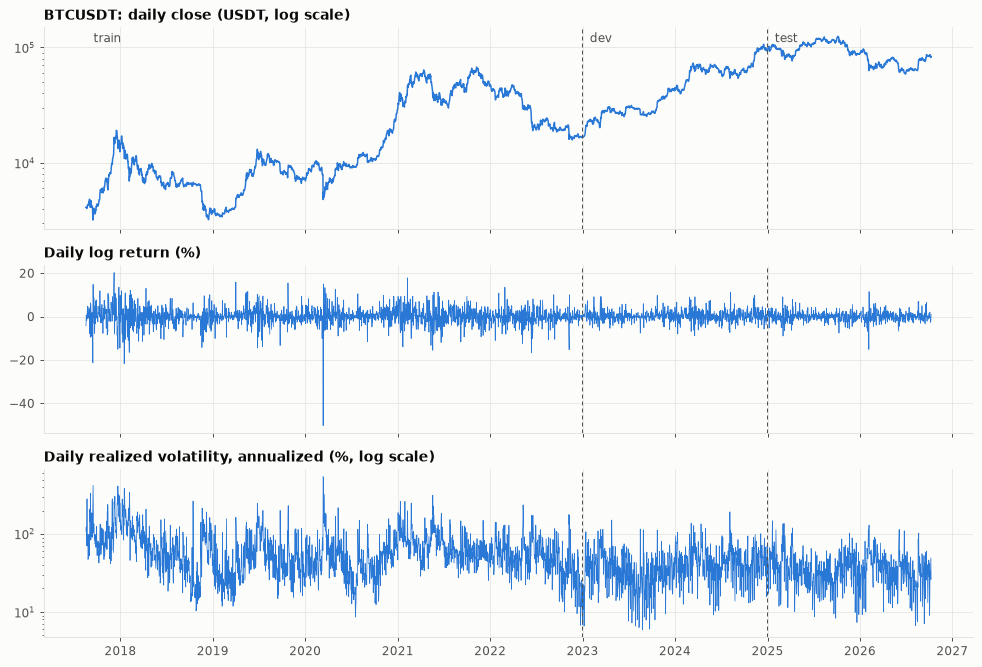

In [7]:
d = daily[MAIN]
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.2, 1, 1]})
axes[0].plot(d.index, d["close"], color=BLUE)
axes[0].set_yscale("log"); axes[0].set_title(f"{MAIN}: daily close (USDT, log scale)")
axes[1].plot(d.index, 100 * d["ret"], color=BLUE, linewidth=0.6)
axes[1].set_title("Daily log return (%)")
axes[2].plot(d.index, 100 * np.sqrt(d["rv"] * DAYS_PER_YEAR), color=BLUE, linewidth=0.6)
axes[2].set_yscale("log"); axes[2].set_title("Daily realized volatility, annualized (%, log scale)")
for ax in axes:
    mark_splits(ax)
top = axes[0].get_ylim()[1]
for label, x in [("train", d.index[0]), ("dev", pd.Timestamp(TRAIN_END, tz="UTC")), ("test", pd.Timestamp(DEV_END, tz="UTC"))]:
    axes[0].annotate(label, (x, top), xytext=(6, -12), textcoords="offset points", color=MUTED)
fig.tight_layout(); plt.show()

The bottom panel already shows what the idea is about: volatility moves in long swings (calm stretches in
2018-19, 2023 and 2025, turbulent ones in early 2018, March 2020, 2021 and 2022), and it has drifted
downwards over the years as the market matured.

### 2.1 Stylized facts

Two properties decide which models can work: the shape of the return distribution and how much memory the
series has.

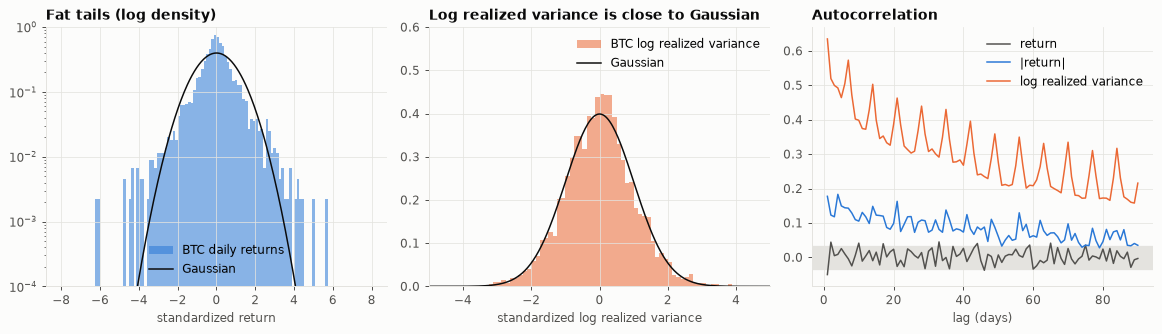

excess kurtosis: returns 16.0, log realized variance 0.35
lag-1 autocorrelation: returns -0.050, |returns| +0.177, log realized variance +0.635


In [8]:
r = d["ret"]
z = ((r - r.mean()) / r.std()).to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

grid = np.linspace(-8, 8, 400)
axes[0].hist(z, bins=120, range=(-8, 8), density=True, color=BLUE, alpha=0.55, label="BTC daily returns")
axes[0].plot(grid, stats.norm.pdf(grid), color=INK, label="Gaussian")
axes[0].set_yscale("log"); axes[0].set_ylim(1e-4, 1); axes[0].set_xlabel("standardized return")
axes[0].set_title("Fat tails (log density)"); axes[0].legend(loc="lower center")

log_rv = np.log(d["rv"])
zrv = ((log_rv - log_rv.mean()) / log_rv.std()).to_numpy()
axes[1].hist(zrv, bins=80, range=(-5, 5), density=True, color=ORANGE, alpha=0.55, label="BTC log realized variance")
axes[1].plot(grid, stats.norm.pdf(grid), color=INK, label="Gaussian")
axes[1].set_xlim(-5, 5); axes[1].set_ylim(0, 0.6); axes[1].set_xlabel("standardized log realized variance")
axes[1].set_title("Log realized variance is close to Gaussian"); axes[1].legend()

lags = np.arange(1, 91)
for series, label, color in [(r, "return", MUTED), (r.abs(), "|return|", BLUE), (log_rv, "log realized variance", ORANGE)]:
    axes[2].plot(lags, [series.autocorr(k) for k in lags], color=color, label=label)
band = 1.96 / np.sqrt(len(r))
axes[2].axhspan(-band, band, color=GRID, zorder=0)
axes[2].set_xlabel("lag (days)"); axes[2].set_title("Autocorrelation"); axes[2].legend()
fig.tight_layout(); plt.show()

print(f"excess kurtosis: returns {r.kurt():.1f}, log realized variance {log_rv.kurt():.2f}")
print(f"lag-1 autocorrelation: returns {r.autocorr(1):+.3f}, |returns| {r.abs().autocorr(1):+.3f}, log realized variance {log_rv.autocorr(1):+.3f}")

In [9]:
# The autocorrelation of log realized variance peaks every 7 days: is there a day-of-week pattern?
weekday = pd.DataFrame({s.replace("USDT", ""): np.log(daily[s]["rv"]).groupby(daily[s].index.dayofweek).mean() for s in SYMBOLS})
weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekend_ratio = np.exp(0.5 * (weekday.loc[["Sat", "Sun"]].mean() - weekday.loc["Mon":"Fri"].mean()))
print("Mean log realized variance by day of the week:")
display(weekday.T)
print("Weekend volatility as a share of weekday volatility:")
display(weekend_ratio.to_frame("ratio").T)

Mean log realized variance by day of the week:


,Mon,Tue,Wed,Thu,Fri,Sat,Sun
BTC,-7.1885,-7.2727,-7.2165,-7.2591,-7.2548,-8.1978,-7.7910
ETH,-6.6759,-6.7685,-6.6669,-6.7262,-6.7605,-7.4718,-7.1437
BNB,-6.7967,-6.8587,-6.8022,-6.8367,-6.8976,-7.4137,-7.2628
SOL,-6.0457,-6.1016,-6.0505,-6.1088,-6.1075,-6.7350,-6.5191
XRP,-6.5506,-6.6570,-6.6255,-6.6890,-6.6694,-7.2981,-7.1621


Weekend volatility as a share of weekday volatility:


,BTC,ETH,BNB,SOL,XRP
ratio,0.6852,0.7452,0.7789,0.7618,0.7439


**What this tells us.**

- **Returns have no usable memory** (autocorrelation inside the noise band), so the *direction* of the market
  is not what a regime model can learn from daily data. Regimes here are **volatility regimes**.
- **Volatility has long memory.** The autocorrelation of $|r_t|$ is positive for months. That is the signal a
  regime model exploits.
- **Realized variance is a much cleaner signal than the return.** Its lag-1 autocorrelation is about 0.64
  against 0.18 for $|r_t|$, and its logarithm is close to Gaussian, which suits Gaussian models. A single
  squared daily return is a very noisy picture of that day's variance.
- **Volatility has a weekly cycle.** The autocorrelation of log realized variance peaks at lags 7, 14, 21
  and so on. The table above shows why: volatility on Saturdays and Sundays is only 69 to 78% of the weekday
  level for every coin. Crypto trades all week, but much of the activity follows traditional market hours.

### 2.2 Feature set and labels

| | Choice | Why |
| --- | --- | --- |
| **Observations (features)** | `ret`, the daily log return; `log rv`, the log realized variance | The return is what we ultimately model. Log realized variance is the low-noise view of the regime variable. |
| **Possible extras** | log volume change, high-low range, returns of other coins | Not used yet. Volume has a strong trend and needs detrending first. |
| **Labels** | **None.** | Nobody knows the true regime of a day, so there is nothing to supervise on. |
| **Evaluation target** | next-day return density and next-day realized variance | In place of labels, models are scored on how well they predict tomorrow from today's regime belief. |

Because there are no labels, "accuracy" is not available. The models are compared on (a) out-of-sample
predictive scores, (b) properties of the regimes themselves, such as persistence, and (c) agreement between
the two methods.

## 3. Preprocessing and split

### 3.1 Preprocessing decisions

| Issue found in the data | Decision |
| --- | --- |
| Prices are non-stationary | Model **log returns**, never prices. |
| Outage days have fewer than 24 bars | Keep the return (the price change is real). **Exclude the day from realized-variance scoring**, where `rv` is understated. |
| Off-hour bars after the February 2018 outage | Keep, assign to the UTC day they start in. |
| Extreme days (for example 12 March 2020, -50%) | **Keep.** They are real and are exactly what a crash regime should explain. No winsorizing. |
| Realized variance is strictly positive and skewed | Use its **logarithm**. |
| Scale of the features | No standardization needed for the models used here. If added later, fit the scaler on train only. |
| Weekend volatility is 22 to 31% lower | **Not removed yet.** A regime model can mistake weekends for a calm regime, so the full experiment should subtract a day-of-week effect (estimated on train) from log realized variance. |
| Level of volatility drifts over the years | Not removed here. It is the main threat to models fitted once on old data, see section 3.2. |

In [10]:
splits = {s: rg.chrono_split(daily[s], TRAIN_END, DEV_END) for s in SYMBOLS}

rows = []
for s in SYMBOLS:
    for name, part in splits[s].items():
        rows.append({
            "symbol": s, "split": name, "first day": part.index[0].strftime("%Y-%m-%d"),
            "last day": part.index[-1].strftime("%Y-%m-%d"), "days": len(part),
            "incomplete days": int((~part["complete"]).sum()),
            "volatility %/year": 100 * part["ret"].std() * np.sqrt(DAYS_PER_YEAR),
            "mean log rv": np.log(part["rv"]).mean(),
            "excess kurtosis": part["ret"].kurt(),
        })
split_table = pd.DataFrame(rows).set_index(["symbol", "split"])

# Save the split data for later experiments (data/ is ignored by git).
out_dir = bd.DATA_DIR / "processed" / "market_regimes"
out_dir.mkdir(parents=True, exist_ok=True)
for s in SYMBOLS:
    pd.concat([part.assign(split=name) for name, part in splits[s].items()]).to_parquet(out_dir / f"{s}_daily.parquet")

split_table

first day    last day  days  incomplete days  volatility %/year  mean log rv  excess kurtosis
symbol  split                                                                                                
BTCUSDT train  2017-08-18  2022-12-31  1962               28            79.1055      -7.0706          13.5656
        dev    2023-01-01  2024-12-31   731                1            48.3138      -7.9415           2.3573
        test   2025-01-01  2026-10-09   647                0            43.3958      -8.0674           5.0690
ETHUSDT train  2017-08-18  2022-12-31  1962               28           101.0492      -6.5126          10.5522
        dev    2023-01-01  2024-12-31   731                1            56.0033      -7.5969           3.5839
        test   2025-01-01  2026-10-09   647                0            69.1059      -7.2233           4.1721
BNBUSDT train  2017-11-07  2022-12-31  1881               27           115.2303      -6.4253          15.3809
        dev    2023-01-01  2024-12-31   731                1            51.5985      -7.6641           4.1300
        test   2025-01-01  2026-10-09   647                0            48.8808      -7.8251           4.7523
SOLUSDT train  2020-08-12  2022-12-31   872                9           148.8086      -5.5823           5.9783
        dev    2023-01-01  2024-12-31   731                1            89.2021      -6.4550           2.7151
        test   2025-01-01  2026-10-09   647                0            76.9540      -6.8770           4.2688
XRPUSDT train  2018-05-05  2022-12-31  1702               24           110.7875      -6.5464          14.2857
        dev    2023-01-01  2024-12-31   731                1            80.7500      -7.1743          41.8935
        test   2025-01-01  2026-10-09   647                0            75.1437      -7.0794           9.3826

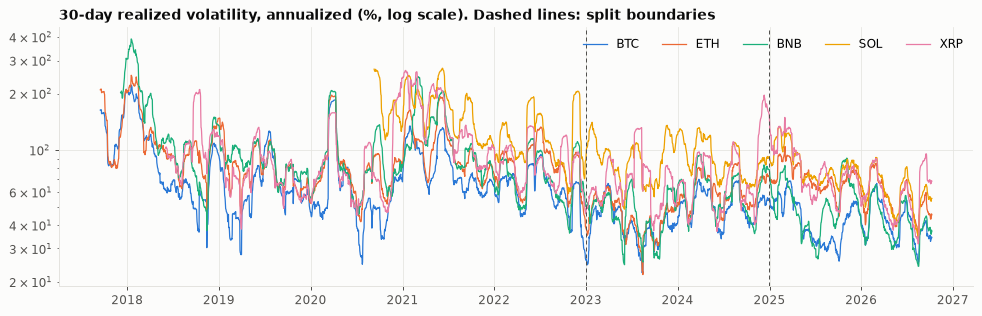

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for s in SYMBOLS:
    vol = 100 * np.sqrt(daily[s]["rv"].rolling(30).mean() * DAYS_PER_YEAR)
    ax.plot(vol.index, vol, color=SERIES_COLOR[s], label=s.replace("USDT", ""), linewidth=1.0)
ax.set_yscale("log"); mark_splits(ax)
ax.set_title("30-day realized volatility, annualized (%, log scale). Dashed lines: split boundaries")
ax.legend(ncol=5, loc="upper right"); fig.tight_layout(); plt.show()

### 3.2 The split

**Chronological, never shuffled:** train to 2022-12-31, dev 2023 and 2024, test 2025-01-01 to 2026-10-09.
For BTC that is 1,962 / 731 / 647 days (59% / 22% / 19%). The same dates are used for every coin, so that
results across coins refer to the same market periods.

- **Train** contains the 2017-18 bubble and crash, the March 2020 crash, the 2021 bull market and the 2022
  collapses (Terra, FTX): several full volatility cycles.
- **Dev** is used to choose model settings (number of states, minimum segment length, and so on).
- **Test** is touched only by fixed baselines in this notebook, and once by the final models later.

**The split exposes a distribution shift.** BTC's annual volatility is about 79% in train, 48% in dev and 43%
in test. Every coin is much calmer after 2022 than in train (ETH rises again in test, to 69%, but stays well
below its train level of 101%). For BTC tail risk also falls (excess kurtosis 14 in train, 2 to 5
afterwards). This is real, not a data problem: the market matured. Any model fitted once
on train has learned volatility levels that are too high for the later years. The evaluation therefore has
to reward models that adapt, and the final protocol should refit models as time moves forward.

### 3.3 Leakage checklist

| Risk | How it is handled |
| --- | --- |
| Random split mixes future into the past | Splits are by date only (`rg.chrono_split`, tested for order and no overlap). |
| Forecast for day $t$ uses day $t$ | Every forecast function is causal: value $t$ uses data before $t$ only. Tested by changing future values and checking that earlier outputs do not move. |
| Realized variance of day $t$ used to predict day $t$ | `rv` of day $t$ is only known at the end of day $t$. It enters forecasts for $t+1$ onwards, never for $t$. |
| HMM smoothing and Viterbi look at the whole series | Used only to *describe* regimes inside train. All out-of-sample scores use the forward filter. |
| MDL segmentation is retrospective | For forecasting, the segmentation is recomputed each day on data up to yesterday. |
| Parameters or thresholds tuned on test | All fitting uses train, all choices use dev. Candidate models are not scored on test here. |
| Overlapping windows across the split boundary | Rolling statistics at the start of dev use the last train days. That is past data, so it is allowed. |

## 4. Baseline

### 4.1 Task, metrics and protocol

**Task.** At the end of day $t-1$, give a probability distribution for the return of day $t$. A regime model
does this through its belief about the current regime. Scoring the forecast distribution turns an
unsupervised problem into one with an objective, out-of-sample measure.

**Metrics.**

| Metric | Definition | Why |
| --- | --- | --- |
| **Log score** (main) | mean of $\log p(r_t \mid \text{past})$, in nats per day, higher is better | A proper scoring rule: it is maximized only by the true distribution, and it judges the whole density, including the tails. Its negative is the code length of the data under the model, which makes it the natural common currency for an MDL comparison. |
| **QLIKE** | mean of $RV_t/\hat\sigma_t^2 - \log(RV_t/\hat\sigma_t^2) - 1$, lower is better | Scores the variance forecast $\hat\sigma_t^2$ against realized variance. It stays a valid ranking when the variance proxy is noisy (Patton, 2011). |
| **RV MSE** | mean squared error of the variance forecast | Reported for reference only: it is dominated by a few extreme days. |
| **Regime persistence** | number of regime switches, typical run length | A regime that flips every other day is not a regime. Only applies to regime models. |

**Protocol.**

1. Fit all parameters on **train**.
2. Run the model forward through dev and test **without refitting**, producing one-step-ahead forecasts.
3. Report the mean score over **dev** and over **test** separately. Outage days are excluded from QLIKE.
4. Compare two models through the daily score differences, with a standard error that allows for
   autocorrelation (Newey-West), so that a difference is only called real when it exceeds the noise.

**Baselines.** None of them has a notion of regimes. A regime model has to beat them to be worth its
complexity.

| Baseline | Forecast for day $t$ |
| --- | --- |
| Constant Gaussian | One Gaussian with the train mean and variance. "No regimes, no dynamics." |
| Constant Student-t | One fat-tailed distribution fitted on train. Separates "fat tails" from "changing volatility". |
| Rolling 30-day Gaussian | Zero mean, variance of the last 30 days. |
| **EWMA Gaussian** (the fixed baseline) | Zero mean, exponentially weighted variance with $\lambda = 0.94$ (RiskMetrics). Nothing is fitted. |
| GARCH(1,1), Gaussian and Student-t | The standard volatility model, fitted on train. The strong reference. |

In [12]:
from arch import arch_model

def score_table(models, d, parts):
    # models: name -> (daily log score, variance forecast), both aligned with d.
    rv, ok = d["rv"].to_numpy(), d["complete"].to_numpy()
    position = {"dev": d.index.isin(parts["dev"].index), "test": d.index.isin(parts["test"].index)}
    rows = {}
    for name, (loglik, var) in models.items():
        row = {}
        for split, mask in position.items():
            scored = mask & ok
            row[(split, "log score")] = loglik[mask].mean()
            row[(split, "QLIKE")] = rg.qlike(rv[scored], var[scored])
            row[(split, "RV MSE x1e6")] = 1e6 * np.mean((rv[scored] - var[scored]) ** 2)
        rows[name] = row
    table = pd.DataFrame(rows).T
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    return table

def baseline_models(d, parts):
    r = d["ret"].to_numpy()
    train = parts["train"]["ret"].to_numpy()
    n = len(r)
    models = {}

    mu, var = train.mean(), train.var()
    models["Constant Gaussian"] = (rg.gaussian_logpdf(r, mu, var), np.full(n, var))

    df_t, loc_t, scale_t = stats.t.fit(train)
    t_var = scale_t**2 * df_t / (df_t - 2) if df_t > 2 else np.inf
    models["Constant Student-t"] = (stats.t.logpdf(r, df_t, loc_t, scale_t), np.full(n, t_var))

    rolling = pd.Series(r**2).rolling(30).mean().shift(1).bfill().to_numpy()
    models["Rolling 30-day Gaussian"] = (rg.gaussian_logpdf(r, 0.0, rolling), rolling)

    ewma = rg.ewma_variance(r, lam=0.94)
    models["EWMA Gaussian (fixed baseline)"] = (rg.gaussian_logpdf(r, 0.0, ewma), ewma)

    for dist, label in [("normal", "Gaussian"), ("t", "Student-t")]:
        # Returns are scaled to percent for the optimizer and scaled back afterwards.
        fit = arch_model(100 * train, vol="GARCH", p=1, q=1, mean="Constant", dist=dist).fit(disp="off")
        p = fit.params
        garch = rg.garch_variance(100 * r, p["omega"], p["alpha[1]"], p["beta[1]"], p["mu"], init_var=(100 * train).var()) / 1e4
        if dist == "normal":
            loglik = rg.gaussian_logpdf(r, p["mu"] / 100, garch)
        else:
            loglik = rg.student_t_logpdf(r, p["mu"] / 100, garch, p["nu"])
        models[f"GARCH(1,1) {label}"] = (loglik, garch)
    return models

baselines = {s: baseline_models(daily[s], splits[s]) for s in SYMBOLS}
baseline_table = score_table(baselines[MAIN], daily[MAIN], splits[MAIN])
print(f"{MAIN}: baseline scores (log score: higher is better; QLIKE and MSE: lower is better)")
baseline_table

BTCUSDT: baseline scores (log score: higher is better; QLIKE and MSE: lower is better)


dev                         test                   
                               log score  QLIKE RV MSE x1e6 log score  QLIKE RV MSE x1e6
Constant Gaussian                 2.0785 0.9387      1.8262    2.1151 1.0043      1.8587
Constant Student-t                2.2541 1.3277      6.0278    2.3298 1.4184      6.3131
Rolling 30-day Gaussian           2.1962 0.5903      0.6454    2.3461 0.4852      0.4678
EWMA Gaussian (fixed baseline)    2.2311 0.5327      0.6115    2.3818 0.4358      0.4242
GARCH(1,1) Gaussian               2.2119 0.6535      0.8178    2.2980 0.6403      0.6466
GARCH(1,1) Student-t              2.3404 0.5496      0.6718    2.4597 0.4779      0.4811

In [13]:
# Is the gap between baselines larger than the noise? Daily log score minus the EWMA baseline.
def versus(models, reference, d, parts, split="dev"):
    mask = d.index.isin(parts[split].index)
    rows = {}
    for name, (loglik, _) in models.items():
        if name == reference:
            continue
        diff, se = rg.mean_diff_se(loglik[mask], models[reference][0][mask])
        rows[name] = {"log score minus EWMA": diff, "std. error": se, "t-stat": diff / se}
    return pd.DataFrame(rows).T

REF = "EWMA Gaussian (fixed baseline)"
pd.concat({split: versus(baselines[MAIN], REF, daily[MAIN], splits[MAIN], split) for split in ["dev", "test"]}, axis=1)

dev                                    test                   
                        log score minus EWMA std. error  t-stat log score minus EWMA std. error  t-stat
Constant Gaussian                    -0.1526     0.0451 -3.3819              -0.2667     0.0507 -5.2590
Constant Student-t                    0.0229     0.0374  0.6126              -0.0520     0.0407 -1.2779
Rolling 30-day Gaussian              -0.0349     0.0156 -2.2386              -0.0357     0.0113 -3.1636
GARCH(1,1) Gaussian                  -0.0192     0.0343 -0.5593              -0.0838     0.0382 -2.1913
GARCH(1,1) Student-t                  0.1093     0.0313  3.4885               0.0779     0.0283  2.7498

In [14]:
# The same baselines on the other coins: log score and QLIKE on dev and test.
rows = {}
for s in SYMBOLS:
    table = score_table(baselines[s], daily[s], splits[s])
    for name in ["Constant Gaussian", REF, "GARCH(1,1) Student-t"]:
        rows[(s.replace("USDT", ""), name)] = table.loc[name, [("dev", "log score"), ("test", "log score"), ("dev", "QLIKE"), ("test", "QLIKE")]]
pd.DataFrame(rows).T

dev      test    dev   test
                                   log score log score  QLIKE  QLIKE
BTC Constant Gaussian                 2.0785    2.1151 0.9387 1.0043
    EWMA Gaussian (fixed baseline)    2.2311    2.3818 0.5327 0.4358
    GARCH(1,1) Student-t              2.3404    2.4597 0.5496 0.4779
ETH Constant Gaussian                 1.8673    1.7870 1.0241 0.7716
    EWMA Gaussian (fixed baseline)    2.0920    1.8497 0.5003 0.4577
    GARCH(1,1) Student-t              2.1416    1.9881 0.7087 0.5630
BNB Constant Gaussian                 1.7891    1.7987 1.2829 1.3952
    EWMA Gaussian (fixed baseline)    2.1982    2.2714 0.5741 0.4187
    GARCH(1,1) Student-t              2.2588    2.3150 0.6196 0.6159
SOL Constant Gaussian                 1.4538    1.5001 0.7471 1.0383
    EWMA Gaussian (fixed baseline)    1.6664    1.8171 0.3784 0.3359
    GARCH(1,1) Student-t              1.6666    1.8076 0.4304 0.5782
XRP Constant Gaussian                 1.6621    1.6991 1.0285 0.8519
    EWMA Gaussian (fixed baseline)    1.4205    1.8383 1.0431 0.4865
    GARCH(1,1) Student-t              2.0714    1.9880 0.7304 0.5255

### 4.2 How the baselines perform

- **Ignoring volatility dynamics is costly.** The constant Gaussian scores 2.08 nats per day on BTC dev. The
  EWMA baseline reaches 2.23 with no fitted parameter, a gain of 0.15 nats per day. Its variance forecast is
  also much better (QLIKE 0.53 against 0.94).
- **Fat tails matter as much as dynamics.** A *constant* Student-t (2.25) is level with the EWMA Gaussian on
  dev, although it knows nothing about the current volatility. Combining both, GARCH with Student-t errors,
  gives the best log score: 2.34 on dev and 2.46 on test.
- **EWMA has the best variance forecast** (lowest QLIKE on dev and test for BTC), ahead of both GARCH
  variants. GARCH was fitted on the high-volatility train years and pulls its forecasts towards a long-run
  level that is too high for 2023 onwards, the distribution shift from section 3.2. EWMA has no long-run
  level and adapts.
- **The other coins mostly agree.** EWMA beats the constant Gaussian in 9 of the 10 coin-period pairs, and
  GARCH Student-t has the best log score of the three in 9 of 10 (on SOL it is level with EWMA).
- **One instructive failure: XRP on dev.** There the EWMA baseline (1.42) is *worse* than the constant
  Gaussian (1.66). A single day causes it: on 13 July 2023 XRP rose 55% after a court ruling, while the
  EWMA forecast expected a daily volatility of 2%. A Gaussian gives a 27-sigma move essentially zero
  probability, which costs 361 nats, about a quarter of a nat per day averaged over the whole dev period. The
  log score punishes thin tails severely, and that is the main weakness of the fixed baseline.

So there are two bars for a regime model. **To be useful it must beat the EWMA baseline. To be
state of the art it must match GARCH Student-t** on the log score and EWMA on QLIKE.

## 5. Method fit: do the HMM and the MDL segmentation suit this data?

Before building the full experiment, we fit both methods in their simplest form to BTC and check whether
they behave as the idea assumes: a small number of **persistent** regimes that both methods agree on.

### 5.1 Gaussian HMM on daily returns

In [15]:
d, parts = daily[MAIN], splits[MAIN]
r = d["ret"].to_numpy()
rv = d["rv"].to_numpy()
log_rv = np.log(rv)
n_train = len(parts["train"])
train_r, train_lrv = r[:n_train], log_rv[:n_train]
dev_mask = d.index.isin(parts["dev"].index)
dev_ok = dev_mask & d["complete"].to_numpy()

def persistence(states):
    runs = rg.run_lengths(states)
    return {"switches in train": len(runs) - 1, "median run (days)": float(np.median(runs))}

start = time.time()
hmm_ret, rows = {}, {}
for k in [2, 3, 4, 5]:
    model = rg.fit_gaussian_hmm(train_r, n_states=k, n_init=20)
    params = rg.hmm_params(model)
    out = rg.hmm_filter(r, **params)
    hmm_ret[k] = (model, params, out)
    train_ll = out["loglik"][:n_train].sum()
    rows[k] = {
        "parameters": rg.hmm_n_params(k),
        "train log-lik": train_ll,
        "BIC": rg.bic(train_ll, rg.hmm_n_params(k), n_train),
        "dev log score": out["loglik"][dev_mask].mean(),
        "dev QLIKE": rg.qlike(rv[dev_ok], out["var"][dev_ok]),
        "state volatilities %/day": np.round(100 * np.sqrt(params["variances"]), 1).tolist(),
        "P(stay in state)": np.round(np.diag(params["transmat"]), 2).tolist(),
        **persistence(model.predict(train_r.reshape(-1, 1))),
    }
single_ll = rg.gaussian_logpdf(train_r, train_r.mean(), train_r.var()).sum()
print(f"single Gaussian: train log-lik {single_ll:.1f}, BIC {rg.bic(single_ll, 2, n_train):.1f}   ({time.time() - start:.0f}s)")
pd.DataFrame(rows).T.rename_axis("states")

single Gaussian: train log-lik 3464.2, BIC -6913.3   (35s)


,parameters,train log-lik,BIC,dev log score,dev QLIKE,state volatilities %/day,P(stay in state),switches in train,median run (days)
states,,,,,,,,,
2,7,"3,716.3871","-7,379.7021",2.2614,0.8552,"[2.0, 6.4]","[0.77, 0.58]",331,3.0000
3,14,"3,763.0395","-7,419.9349",2.2951,0.6987,"[1.8, 4.8, 7.5]","[0.69, 0.54, 0.95]",347,2.0000
4,23,"3,789.5125","-7,404.6455",2.3073,0.6896,"[1.7, 4.8, 4.8, 12.5]","[0.72, 0.94, 0.42, 0.35]",167,2.0000
5,34,"3,807.0803","-7,356.3821",2.3080,0.6233,"[1.6, 2.6, 5.2, 6.5, 8.5]","[0.88, 0.49, 0.3, 0.25, 0.95]",433,1.0000


**The HMM fits, but not as a regime model.**

- It improves the likelihood a lot over a single Gaussian, and BIC picks 3 states.
- Yet most states are **not persistent.** Apart from one high-volatility state (probability of staying
  about 0.95), the probability of staying in a state is between 0.25 and 0.9, the median visit lasts 1 to
  3 days, and the most likely state path switches 167 to 433 times in 1,962 days. A regime in the sense of
  the idea (a trending or a crash *period*) should last weeks or months.
- What the model has learned is a **mixture of Gaussians that explains the fat tails**: a calm day and a
  wild day are assigned to different states almost independently of yesterday. A single daily return says
  too little about that day's variance for the model to recognize a persistent state.

This matches the literature: Koki et al. (2020) report that HMM states on crypto returns "are not
persistent, but present frequent alternations", and the lack of persistence of Gaussian HMMs on daily
returns is the motivation for the jump models of Nystrup et al.

### 5.2 MDL segmentation on daily returns

`rg.mdl_segment` cuts the series into pieces, each coded as an i.i.d. Gaussian with its own mean and
variance, and returns the cut with the shortest total code length (data bits plus parameter bits plus the
bits for the cut positions). It is exact (dynamic programming) and has no penalty to tune.

In [16]:
def segments(x, min_len):
    breaks, code_length = rg.mdl_segment(x, min_len=min_len)
    starts = [0] + breaks[:-1]
    return breaks, starts, code_length

rows = {}
for min_len in [10, 20, 30]:
    breaks, starts, code_length = segments(train_r, min_len)
    lengths = np.diff([0] + breaks)
    rows[min_len] = {"segments": len(breaks), "code length (nats)": code_length,
                     "shortest (days)": lengths.min(), "median (days)": np.median(lengths), "longest (days)": lengths.max()}
display(pd.DataFrame(rows).T.rename_axis("minimum segment length"))

# Code length of the train returns under each model family (two-part code, lower is better).
breaks_r, starts_r, mdl_code = segments(train_r, 20)
code_lengths = {"single Gaussian": -single_ll + 0.5 * 2 * np.log(n_train), "MDL segmentation (min length 20)": mdl_code}
for k, (_, _, out) in hmm_ret.items():
    code_lengths[f"HMM, {k} states"] = -out["loglik"][:n_train].sum() + 0.5 * rg.hmm_n_params(k) * np.log(n_train)
pd.Series(code_lengths, name="code length of train returns (nats)").to_frame()

,segments,code length (nats),shortest (days),median (days),longest (days)
minimum segment length,,,,,
10,17.0000,"-3,605.6506",10.0000,58.0000,452.0000
20,15.0000,"-3,595.9453",20.0000,67.0000,504.0000
30,13.0000,"-3,583.2205",30.0000,120.0000,504.0000


,code length of train returns (nats)
single Gaussian,"-3,456.6291"
MDL segmentation (min length 20),"-3,595.9453"
"HMM, 2 states","-3,689.8511"
"HMM, 3 states","-3,709.9675"
"HMM, 4 states","-3,702.3228"
"HMM, 5 states","-3,678.1911"


**The MDL segmentation does what the idea asks:** it finds 13 to 17 segments in 5.4 years, with a median
length of two to four months, and the cut points barely move when the minimum segment length changes. These are regimes on the
time scale we care about.

**But it compresses the data worse than the HMM** (about -3,596 nats against -3,710 for the 3-state HMM,
lower is better). The reason is the same fat tails: inside a segment the Gaussian has to cover both the calm
and the wild days, while the HMM can switch state for a single day.

**So on raw returns the two methods answer different questions.** The HMM models day-to-day mixing, the MDL
segmentation models slow level changes. Their outputs cannot agree, as the next cells show.

### 5.3 The same two methods on log realized variance

Section 2.1 showed that log realized variance is a far cleaner view of the volatility state. If the lack of
persistence comes from the noise in single returns, both methods should behave better on it.

In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

breaks_v, starts_v, _ = segments(train_lrv, 20)
seg_labels_r = rg.segment_labels(n_train, breaks_r)
seg_labels_v = rg.segment_labels(n_train, breaks_v)
seg_level_r = np.array([np.log(train_r[a:b].var()) for a, b in zip(starts_r, breaks_r)])   # log variance per segment
seg_level_v = np.array([train_lrv[a:b].mean() for a, b in zip(starts_v, breaks_v)])

def near(points, others, tolerance):
    # Share of `points` that have one of `others` within `tolerance` days.
    return float(np.mean([np.min(np.abs(others - p)) <= tolerance for p in points])) if len(points) and len(others) else np.nan

hmm_lrv, rows = {}, {}
for k in [2, 3, 4]:
    # HMM that observes log realized variance only.
    model = rg.fit_gaussian_hmm(train_lrv, n_states=k, n_init=10)
    hmm_lrv[k] = model
    states_v = model.predict(train_lrv.reshape(-1, 1))
    states_r = hmm_ret[k][0].predict(train_r.reshape(-1, 1))
    # MDL segments are all different; group them into k volatility levels to compare with k HMM states.
    groups_r = KMeans(k, n_init=10, random_state=0).fit(seg_level_r.reshape(-1, 1)).labels_[seg_labels_r]
    groups_v = KMeans(k, n_init=10, random_state=0).fit(seg_level_v.reshape(-1, 1)).labels_[seg_labels_v]
    switches_v = np.flatnonzero(np.diff(states_v)) + 1
    rows[k] = {
        ("returns", "HMM switches"): persistence(states_r)["switches in train"],
        ("returns", "MDL breaks"): len(breaks_r) - 1,
        ("returns", "agreement (ARI)"): adjusted_rand_score(states_r, groups_r),
        ("log realized variance", "HMM switches"): len(switches_v),
        ("log realized variance", "HMM median run (days)"): persistence(states_v)["median run (days)"],
        ("log realized variance", "MDL breaks"): len(breaks_v) - 1,
        ("log realized variance", "agreement (ARI)"): adjusted_rand_score(states_v, groups_v),
        ("log realized variance", "MDL breaks within 10 days of an HMM switch"): near(np.array(breaks_v[:-1]), switches_v, 10),
    }
agreement = pd.DataFrame(rows).T.rename_axis("states")
agreement.columns = pd.MultiIndex.from_tuples(agreement.columns)
agreement.T

states                                                                  2        3        4
returns               HMM switches                               331.0000 347.0000 167.0000
                      MDL breaks                                  14.0000  14.0000  14.0000
                      agreement (ARI)                             -0.0878   0.1594   0.0627
log realized variance HMM switches                                35.0000  73.0000  92.0000
                      HMM median run (days)                       26.0000  14.0000  14.0000
                      MDL breaks                                  24.0000  24.0000  24.0000
                      agreement (ARI)                              0.6305   0.4444   0.2899
                      MDL breaks within 10 days of an HMM switch   0.5000   0.6250   0.9583

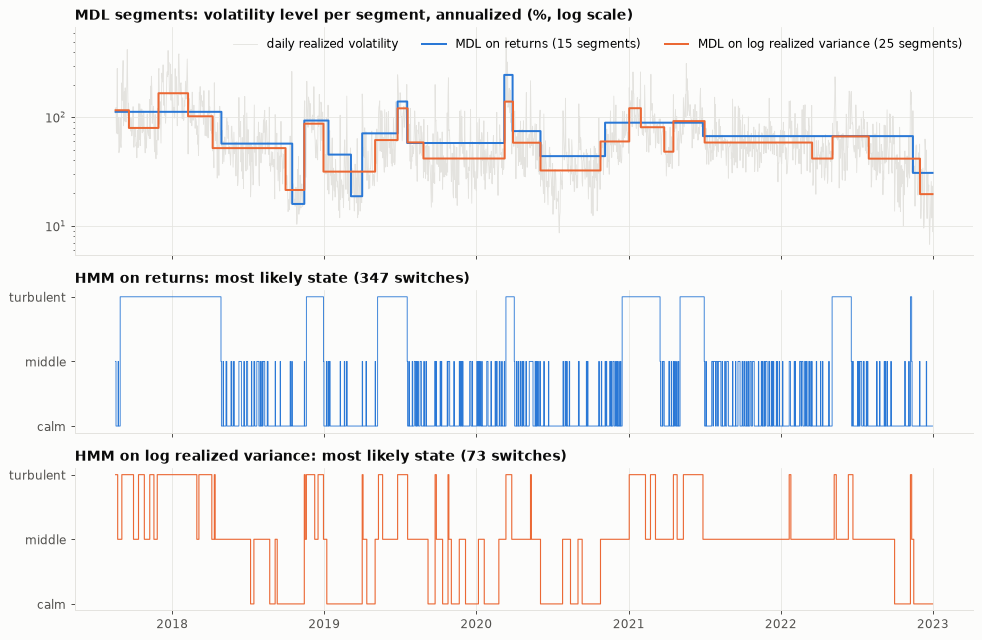

In [18]:
# One picture of the four segmentations on the train period (3 HMM states).
K = 3
dates = parts["train"].index
states_r = hmm_ret[K][0].predict(train_r.reshape(-1, 1))
states_v = hmm_lrv[K].predict(train_lrv.reshape(-1, 1))
# Order the log-rv HMM states by their mean, so that state 0 is the calmest in both models.
rank_v = np.argsort(np.argsort(hmm_lrv[K].means_[:, 0]))
states_v = rank_v[states_v]

def annual_pct(log_variance):
    return 100 * np.sqrt(np.exp(log_variance) * DAYS_PER_YEAR)

fig, axes = plt.subplots(3, 1, figsize=(11, 7.2), sharex=True, gridspec_kw={"height_ratios": [1.6, 1, 1]})
axes[0].plot(dates, annual_pct(train_lrv), color=GRID, linewidth=0.7, label="daily realized volatility")
axes[0].step(dates, annual_pct(seg_level_r[seg_labels_r]), where="post", color=BLUE, linewidth=1.6, label=f"MDL on returns ({len(breaks_r)} segments)")
axes[0].step(dates, annual_pct(seg_level_v[seg_labels_v]), where="post", color=ORANGE, linewidth=1.6, label=f"MDL on log realized variance ({len(breaks_v)} segments)")
axes[0].set_yscale("log"); axes[0].set_title("MDL segments: volatility level per segment, annualized (%, log scale)")
axes[0].legend(ncol=3, loc="upper right")
axes[1].step(dates, states_r, where="post", color=BLUE, linewidth=0.7)
axes[1].set_title(f"HMM on returns: most likely state ({persistence(states_r)['switches in train']} switches)")
axes[2].step(dates, states_v, where="post", color=ORANGE, linewidth=0.9)
axes[2].set_title(f"HMM on log realized variance: most likely state ({persistence(states_v)['switches in train']} switches)")
for ax in axes[1:]:
    ax.set_yticks(range(K)); ax.set_yticklabels(["calm", "middle", "turbulent"]); ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

**Observing realized variance fixes the fit.**

- On **returns**, the HMM switches hundreds of times, the MDL segmentation about 14 times, and their
  agreement (adjusted Rand index) is close to zero: no better than chance.
- On **log realized variance**, the HMM becomes persistent (with 2 states: 35 switches in 5.4 years and a
  median run of 26 days), and it **agrees with the MDL segmentation**: an adjusted Rand index of 0.63 with
  2 states and 0.44 with 3. Half or more of the MDL breakpoints lie within 10 days of an HMM switch.
- Agreement falls as states are added (0.29 with 4), because extra states split the volatility range into
  bands that the HMM crosses more often. The HMM still switches three to four times as often as the MDL
  segmentation cuts.

Two independent methods finding largely the same structure is the strongest evidence available, without
labels, that the regimes are a property of the data and not of a model.

### 5.4 Are the regimes useful out of sample?

Last check: do the candidate models predict the dev period better than the baselines? Three candidates, all
fitted on train and run forward with causal filters:

- **HMM on returns**, as proposed in the idea.
- **HMM on returns and log realized variance jointly**: each state has a return distribution and a
  realized-variance distribution. Yesterday's realized variance sharpens the belief about today's state.
- **MDL forecaster**: each day, re-segment all data up to yesterday and forecast with the variance of the
  latest segment. This is the segmentation used as an online predictor.

In [19]:
candidates = {}
for k in [2, 3, 4, 5]:
    out = hmm_ret[k][2]
    candidates[f"HMM on returns, {k} states"] = (out["loglik"], out["var"])

obs = np.column_stack([r, log_rv])
start = time.time()
hmm_joint, rows = {}, {}
for k in [2, 3, 4, 5]:
    model = rg.fit_gaussian_hmm(obs[:n_train], n_states=k, n_init=10)
    params = rg.hmm_params(model)
    out = rg.hmm_filter(obs, **params)
    hmm_joint[k] = (model, params, out)
    # Column 0 is the return: its marginal predictive density and variance.
    candidates[f"HMM on returns + log RV, {k} states"] = (out["loglik_marginal"][:, 0], out["var"][:, 0])
    rows[k] = {
        "return volatility by state %/day": np.round(100 * np.sqrt(params["variances"][:, 0]), 1).tolist(),
        "P(stay in state)": np.round(np.diag(params["transmat"]), 2).tolist(),
        **persistence(model.predict(obs[:n_train])),
        "share of dev days by state": np.round(np.bincount(out["filtered"][dev_mask].argmax(axis=1), minlength=k) / dev_mask.sum(), 2).tolist(),
    }
print(f"joint HMM fits: {time.time() - start:.0f}s")
pd.DataFrame(rows).T.rename_axis("states")

joint HMM fits: 10s


,return volatility by state %/day,P(stay in state),switches in train,median run (days),share of dev days by state
states,,,,,
2,"[2.0, 6.0]","[0.9, 0.86]",171,5.0000,"[0.87, 0.13]"
3,"[1.2, 3.2, 7.2]","[0.8, 0.85, 0.84]",235,4.0000,"[0.53, 0.44, 0.03]"
4,"[1.2, 2.4, 4.6, 8.2]","[0.79, 0.69, 0.62, 0.83]",461,3.0000,"[0.43, 0.44, 0.13, 0.0]"
5,"[1.3, 1.5, 2.9, 4.9, 8.6]","[0.91, 0.55, 0.53, 0.56, 0.8]",655,2.0000,"[0.33, 0.28, 0.3, 0.08, 0.0]"


In [20]:
# MDL forecaster on dev: re-segment the returns up to yesterday, use the latest segment's variance.
start = time.time()
mdl_var = np.full(len(r), np.nan)
last_segment_length = []
for t in np.flatnonzero(dev_mask):
    breaks, _ = rg.mdl_segment(r[:t], min_len=20)
    begin = breaks[-2] if len(breaks) > 1 else 0
    mdl_var[t] = r[begin:t].var(ddof=1)
    last_segment_length.append(t - begin)
mdl_loglik = np.where(dev_mask, rg.gaussian_logpdf(r, 0.0, np.where(dev_mask, mdl_var, 1.0)), np.nan)
candidates["MDL forecaster (latest segment)"] = (mdl_loglik, mdl_var)
print(f"MDL forecaster: {time.time() - start:.0f}s, latest segment length: median {np.median(last_segment_length):.0f} days, min {min(last_segment_length)}")

def dev_scores(models):
    rows = {}
    reference = baselines[MAIN][REF][0][dev_mask]
    for name, (loglik, var) in models.items():
        diff, se = rg.mean_diff_se(loglik[dev_mask], reference)
        rows[name] = {"dev log score": loglik[dev_mask].mean(), "dev QLIKE": rg.qlike(rv[dev_ok], var[dev_ok]),
                      "log score minus EWMA": diff, "std. error": se}
    return pd.DataFrame(rows).T

dev_table = pd.concat({"baselines": dev_scores(baselines[MAIN]), "candidates": dev_scores(candidates)})
dev_table

MDL forecaster: 50s, latest segment length: median 189 days, min 20


dev log score  dev QLIKE  log score minus EWMA  std. error
baselines  Constant Gaussian                         2.0785     0.9387               -0.1526      0.0451
           Constant Student-t                        2.2541     1.3277                0.0229      0.0374
           Rolling 30-day Gaussian                   2.1962     0.5903               -0.0349      0.0156
           EWMA Gaussian (fixed baseline)            2.2311     0.5327                0.0000      0.0000
           GARCH(1,1) Gaussian                       2.2119     0.6535               -0.0192      0.0343
           GARCH(1,1) Student-t                      2.3404     0.5496                0.1093      0.0313
candidates HMM on returns, 2 states                  2.2614     0.8552                0.0303      0.0371
           HMM on returns, 3 states                  2.2951     0.6987                0.0639      0.0370
           HMM on returns, 4 states                  2.3073     0.6896                0.0762      0.0360
           HMM on returns, 5 states                  2.3080     0.6233                0.0768      0.0345
           HMM on returns + log RV, 2 states         2.3000     0.5941                0.0688      0.0334
           HMM on returns + log RV, 3 states         2.3132     0.5434                0.0821      0.0341
           HMM on returns + log RV, 4 states         2.3197     0.5256                0.0886      0.0349
           HMM on returns + log RV, 5 states         2.3147     0.5193                0.0836      0.0344
           MDL forecaster (latest segment)           2.2030     0.6157               -0.0281      0.0205

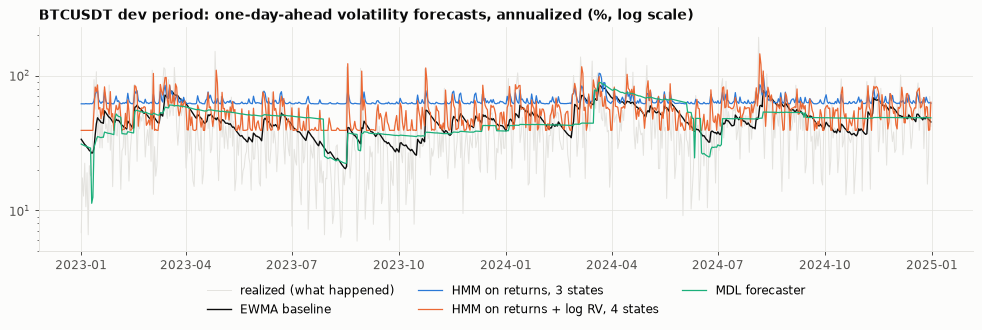

In [21]:
# How the forecasts differ: one-step-ahead volatility forecasts on dev.
best_k = 4
fig, ax = plt.subplots(figsize=(11, 3.8))
dev_dates = d.index[dev_mask]
to_pct = lambda var: 100 * np.sqrt(var[dev_mask] * DAYS_PER_YEAR)
ax.plot(dev_dates, to_pct(rv), color=GRID, linewidth=0.8, label="realized (what happened)")
ax.plot(dev_dates, to_pct(baselines[MAIN][REF][1]), color=INK, linewidth=1.1, label="EWMA baseline")
ax.plot(dev_dates, to_pct(hmm_ret[3][2]["var"]), color=BLUE, linewidth=1.0, label="HMM on returns, 3 states")
ax.plot(dev_dates, to_pct(hmm_joint[best_k][2]["var"][:, 0]), color=ORANGE, linewidth=1.0, label=f"HMM on returns + log RV, {best_k} states")
ax.plot(dev_dates, to_pct(mdl_var), color=AQUA, linewidth=1.0, label="MDL forecaster")
ax.set_yscale("log"); ax.set_title(f"{MAIN} dev period: one-day-ahead volatility forecasts, annualized (%, log scale)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1)); fig.tight_layout(); plt.show()

**Reading the dev results.**

- **Log score: the regime models are competitive, with weak statistical evidence.** Every HMM scores above
  the EWMA baseline, by 0.03 to 0.09 nats per day. The standard error of these differences is about 0.035,
  so only the better models (4 or more states, or with realized variance) are about two standard errors
  ahead, and the 2-state HMM is not distinguishable from the baseline. They gain mostly through fat tails:
  a mixture of states is a fat-tailed distribution. None of them reaches GARCH Student-t (2.34).
- **QLIKE: the plain HMM on returns loses clearly** (0.62 to 0.86 against 0.53 for EWMA). The chart shows
  why: its volatility forecast is almost flat, at a level learned from the turbulent train years. Because
  its states are not persistent, yesterday's state says little about today's, and the forecast falls back
  to the long-run average.
- **Adding realized variance closes that gap.** The joint HMM has a better log score than the HMM on returns
  at every number of states, and with 4 or 5 states its QLIKE (0.52 to 0.53) is level with the EWMA
  baseline. Its states are still short-lived on train, though (median run 2 to 5 days), so it forecasts
  well without yet giving the persistent regimes we want.
- **The MDL forecaster is in the range of the baselines but not better:** slightly below EWMA on both
  metrics (2.20 and 0.62). It reacts late by construction, since a new segment needs 20 days of evidence,
  and its Gaussian has thin tails. Its strength is the description of regimes, not forecasting.

## 6. Summary

| Question | Answer |
| --- | --- |
| Is the data usable? | Yes. 9 years of clean hourly bars for 5 coins, under 0.2% of hours missing, cross-checked against a second source. |
| Is there enough? | 2,250 to 3,340 daily observations per coin. Enough for small models, and hourly data is available for more. |
| Features and labels? | Daily log return and log realized variance. No labels: evaluation is by out-of-sample predictive scores, persistence and agreement between methods. |
| Preprocessing? | Log returns, log realized variance, outage days excluded from variance scoring, no outlier removal. Still to add: a day-of-week adjustment. |
| Split? | By date: train to 2022, dev 2023-24, test 2025-26. Volatility falls strongly from train to dev and test. |
| Baseline? | EWMA Gaussian: 2.23 nats per day on BTC dev and 2.38 on test. Strong reference: GARCH Student-t, 2.34 and 2.46. |
| Do the methods fit? | **Not on raw returns:** the HMM is not persistent and disagrees with MDL. **Yes on log realized variance:** the HMM becomes persistent and agrees with MDL (adjusted Rand index 0.63 with 2 states). |
| Do regimes help prediction? | On BTC dev the HMMs beat the EWMA baseline on the log score by up to 0.09 nats per day (about two standard errors) and match it on QLIKE only when realized variance is observed. None beats GARCH Student-t. |

The full discussion is in [`research/market_regimes_writeup.md`](../../research/market_regimes_writeup.md).